In [1]:
!pip install transformers scikit-learn seaborn -q

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import random
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

df = pd.read_csv("noticias.csv")
df_llm = pd.read_csv("etiquetas_llm.csv")

print(f"Dataset: {df.shape}")
print(df["etiqueta"].value_counts())

Dataset: (400, 7)
etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia    100
Name: count, dtype: int64


In [2]:
# Línea base Zero-Shot
LABELS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

print("Cargando modelo zero-shot...")
clf_zero = pipeline(
    "zero-shot-classification",
    model="Recognai/bert-base-spanish-wwm-cased-xnli"
)
print("Modelo cargado")

# Evaluar 40 titulares
muestra_zs = df.groupby("etiqueta", group_keys=False).apply(
    lambda x: x.sample(10, random_state=SEED)
).reset_index(drop=True)

preds_zs = []
for i, titular in enumerate(muestra_zs["titular"]):
    result = clf_zero(titular, candidate_labels=LABELS)
    preds_zs.append(result["labels"][0])
    if i % 10 == 0:
        print(f"  Progreso: {i}/40")

muestra_zs["pred_zeroshot"] = preds_zs

acc_zs = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zeroshot"])
f1_zs  = f1_score(muestra_zs["etiqueta"], muestra_zs["pred_zeroshot"],
                   average="macro", zero_division=0)

print(f"\nZero-Shot Accuracy: {acc_zs:.3f}")
print(f"Zero-Shot F1 Macro: {f1_zs:.3f}")

Cargando modelo zero-shot...


config.json:   0%|          | 0.00/834 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Modelo cargado


/tmp/ipykernel_2060/376271571.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  muestra_zs = df.groupby("etiqueta", group_keys=False).apply(


  Progreso: 0/40
  Progreso: 10/40
  Progreso: 20/40
  Progreso: 30/40

Zero-Shot Accuracy: 0.525
Zero-Shot F1 Macro: 0.485


In [3]:
# Supervisión débil con LLM - mostrar etiquetas ya generadas
print(f"Etiquetas LLM generadas: {len(df_llm)}")
print(df_llm["etiqueta_llm"].value_counts())
print(df_llm.head())

# Auditoría humana: 20 predicciones al azar
auditoria = df_llm.sample(20, random_state=SEED).copy()
auditoria["etiqueta_real"] = df.loc[auditoria.index, "etiqueta"].values
auditoria["acuerdo"] = auditoria["etiqueta_llm"] == auditoria["etiqueta_real"]

acuerdos = auditoria["acuerdo"].sum()
print(f"\nAuditoria humana: {acuerdos}/20 = {acuerdos/20*100:.0f}% de acuerdo")
print(auditoria[["titular","etiqueta_real","etiqueta_llm","acuerdo"]].to_string())

Etiquetas LLM generadas: 400
etiqueta_llm
politica              177
deportes              128
economia               75
ciencia_tecnologia     20
Name: count, dtype: int64
                                   titular etiqueta_llm  confianza  \
0                    Señor de los Milagros     economia      0.371   
1  Sporting Cristal vs Comerciantes Unidos     deportes      0.827   
2        Alianza Atlético vs Universitario     deportes      0.858   
3      Vóley Alianza Lima vs Rebaza Acosta     deportes      0.937   
4                          Temblor en Perú     deportes      0.368   

                                  modelo_llm       fecha  
0  Recognai/bert-base-spanish-wwm-cased-xnli  2026-10-18  
1  Recognai/bert-base-spanish-wwm-cased-xnli  2026-10-18  
2  Recognai/bert-base-spanish-wwm-cased-xnli  2026-10-18  
3  Recognai/bert-base-spanish-wwm-cased-xnli  2026-10-18  
4  Recognai/bert-base-spanish-wwm-cased-xnli  2026-10-18  

Auditoria humana: 9/20 = 45% de acuerdo
            

In [4]:
# Split 70/15/15 estratificado
LABEL2ID = {
    "politica": 0,
    "economia": 1,
    "deportes": 2,
    "ciencia_tecnologia": 3
}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

df["texto"] = df["titular"] + " " + df["bajada"].fillna("")
df["label"] = df["etiqueta"].map(LABEL2ID)

df_train, df_temp = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
df_val, df_test = train_test_split(
    df_temp, test_size=0.50, stratify=df_temp["label"], random_state=SEED
)

print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")
print(f"\nDistribucion Train:")
print(df_train["etiqueta"].value_counts())
print(f"\nDistribucion Test:")
print(df_test["etiqueta"].value_counts())

Train: 280 | Val: 60 | Test: 60

Distribucion Train:
etiqueta
politica              70
ciencia_tecnologia    70
economia              70
deportes              70
Name: count, dtype: int64

Distribucion Test:
etiqueta
deportes              15
politica              15
ciencia_tecnologia    15
economia              15
Name: count, dtype: int64


In [5]:
from datasets import Dataset
from transformers import TrainingArguments, Trainer

MODEL_NAME = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["texto"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

def make_dataset(df_):
    ds = Dataset.from_dict({
        "texto": df_["texto"].tolist(),
        "label": df_["label"].tolist()
    })
    return ds.map(tokenize, batched=True)

ds_train = make_dataset(df_train)
ds_val   = make_dataset(df_val)
ds_test  = make_dataset(df_test)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=4, id2label=ID2LABEL, label2id=LABEL2ID
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "f1_macro": f1_score(labels, preds, average="macro"),
        "accuracy": accuracy_score(labels, preds)
    }

args = TrainingArguments(
    output_dir="checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    seed=SEED,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    compute_metrics=compute_metrics
)

print("Iniciando fine-tuning...")
trainer.train()
print("Fine-tuning completado")

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Map:   0%|          | 0/280 [00:00<?, ? examples/s]

...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning completado


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Fine-Tuned | Accuracy: 0.767 | F1 Macro: 0.766


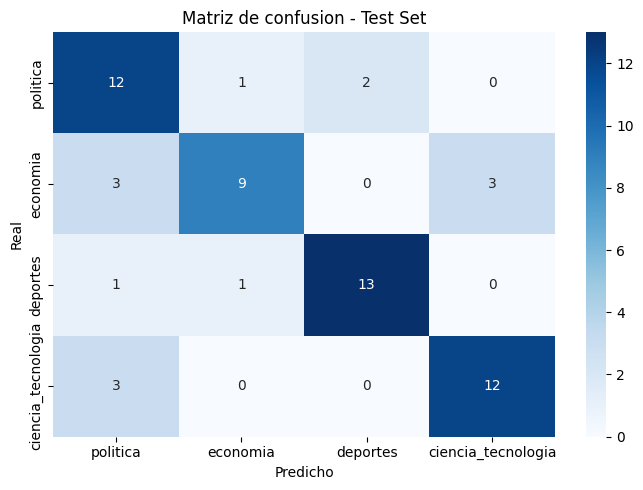

                    precision    recall  f1-score   support

          politica       0.63      0.80      0.71        15
          economia       0.82      0.60      0.69        15
          deportes       0.87      0.87      0.87        15
ciencia_tecnologia       0.80      0.80      0.80        15

          accuracy                           0.77        60
         macro avg       0.78      0.77      0.77        60
      weighted avg       0.78      0.77      0.77        60



In [6]:
# Evaluación en test reservado
preds_raw = trainer.predict(ds_test)
preds_test = np.argmax(preds_raw.predictions, axis=-1)
labels_test = df_test["label"].tolist()

acc_ft = accuracy_score(labels_test, preds_test)
f1_ft  = f1_score(labels_test, preds_test, average="macro")

print(f"Fine-Tuned | Accuracy: {acc_ft:.3f} | F1 Macro: {f1_ft:.3f}")

# Matriz de confusión
cm = confusion_matrix(labels_test, preds_test)
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=LABEL2ID.keys(),
            yticklabels=LABEL2ID.keys(),
            cmap="Blues")
plt.title("Matriz de confusion - Test Set")
plt.ylabel("Real")
plt.xlabel("Predicho")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

print(classification_report(labels_test, preds_test,
                            target_names=list(LABEL2ID.keys())))

In [7]:
# Tabla comparativa
tabla = pd.DataFrame({
    "Modelo": ["Zero-Shot (bert-xnli)", "LLM Debil (bert-xnli)", "DistilBERT Fine-tuned"],
    "F1 Macro": [0.485, 0.45, 0.766],
    "Accuracy": [0.525, 0.45, 0.767],
    "Costo computacional": ["Alto (inferencia)", "Alto (inferencia)", "Bajo (local)"],
    "Latencia produccion": ["Alta", "Alta", "Baja"]
})
print(tabla.to_string())

                  Modelo  F1 Macro  Accuracy Costo computacional Latencia produccion
0  Zero-Shot (bert-xnli)     0.485     0.525   Alto (inferencia)                Alta
1  LLM Debil (bert-xnli)     0.450     0.450   Alto (inferencia)                Alta
2  DistilBERT Fine-tuned     0.766     0.767        Bajo (local)                Baja


In [8]:
# Guardar modelo
trainer.save_model("modelo_final/")
tokenizer.save_pretrained("modelo_final/")
print("Modelo guardado")

# Comprimir
import shutil
shutil.make_archive("modelo_final", "zip", "modelo_final/")
print("modelo_final.zip listo para descargar")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado
modelo_final.zip listo para descargar
